# Image Data Collection, Processing and Facial Recognition Model

Part 2 of Formative 2 (Group 14). Each member has three photos: neutral, smiling and surprised.

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.image_features import (EXPRESSIONS, augment, build_feature_table, detect_face,
                                find_images, load_image)
from src import face_model

IMAGES_DIR = "data/images"
UNAUTHORIZED_DIR = "data/unauthorized/images"
sns.set_theme(style="whitegrid")

## 1. Load and display the images

In [2]:
images = list(find_images(IMAGES_DIR))
members = sorted({m for m, _, _ in images})
print(f"{len(images)} images from {len(members)} members")
pd.crosstab(pd.Series([m for m, _, _ in images], name="member"),
            pd.Series([e for _, e, _ in images], name="expression"))

12 images from 4 members


expression,neutral,smiling,surprised
member,,,
belyse,1,1,1
kyla,1,1,1
rashid,1,1,1
sandrine,1,1,1


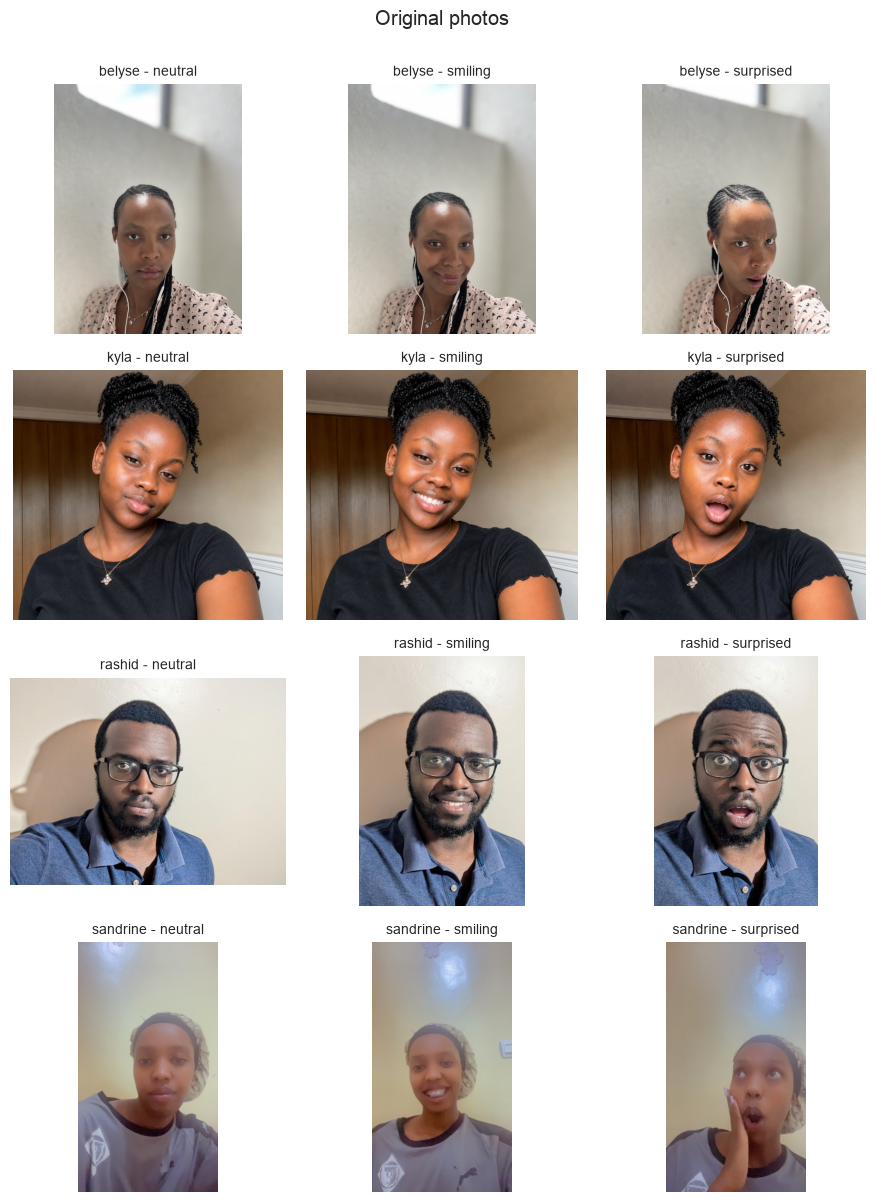

In [3]:
def show(img, ax, title=""):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

lookup = {(m, e): p for m, e, p in images}
fig, axes = plt.subplots(len(members), 3, figsize=(9, 3 * len(members)), squeeze=False)
for i, m in enumerate(members):
    for j, e in enumerate(EXPRESSIONS):
        if (m, e) in lookup:
            show(load_image(lookup[(m, e)]), axes[i, j], f"{m} - {e}")
        else:
            axes[i, j].axis("off")
plt.suptitle("Original photos", y=1.0)
plt.tight_layout()
plt.show()

## 2. Face detection

Each photo is cropped to the face using OpenCV's YuNet face detector, so the background does not affect the features.

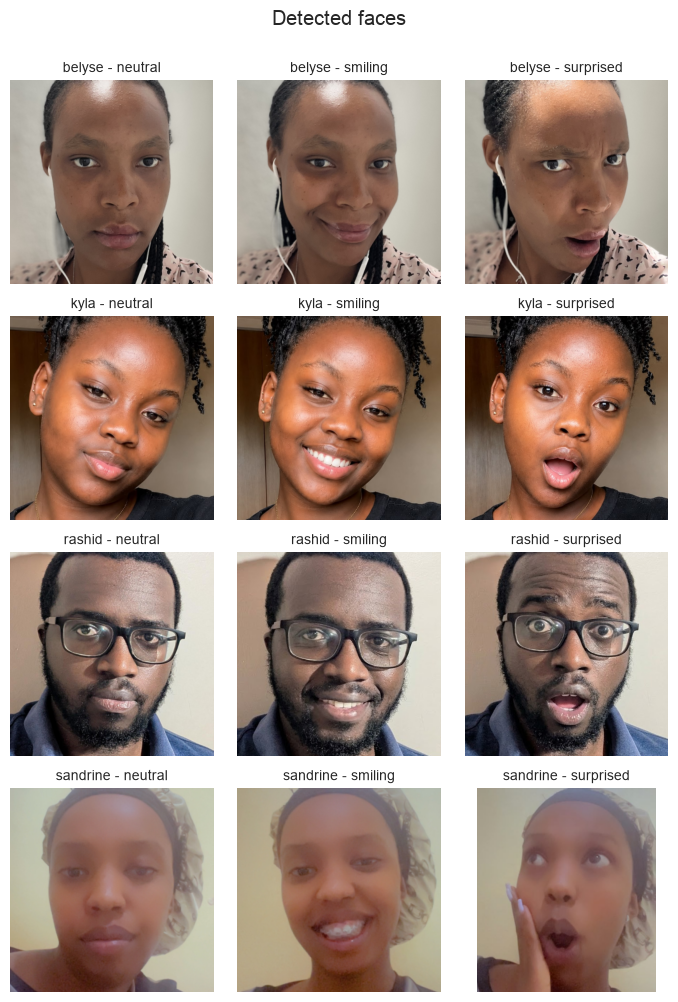

In [4]:
fig, axes = plt.subplots(len(members), 3, figsize=(7, 2.5 * len(members)), squeeze=False)
for i, m in enumerate(members):
    for j, e in enumerate(EXPRESSIONS):
        if (m, e) not in lookup:
            axes[i, j].axis("off")
            continue
        face, found = detect_face(load_image(lookup[(m, e)]))
        show(face, axes[i, j], f"{m} - {e}" + ("" if found else " (no face found)"))
plt.suptitle("Detected faces", y=1.0)
plt.tight_layout()
plt.show()

## 3. Augmentation

Every face crop gets 8 augmented versions: rotation (+15 and -15 degrees), horizontal flip, grayscale, brighter, darker, blur and noise.

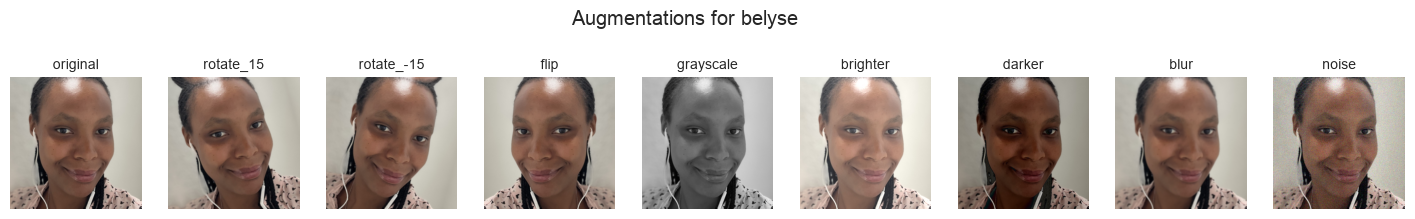

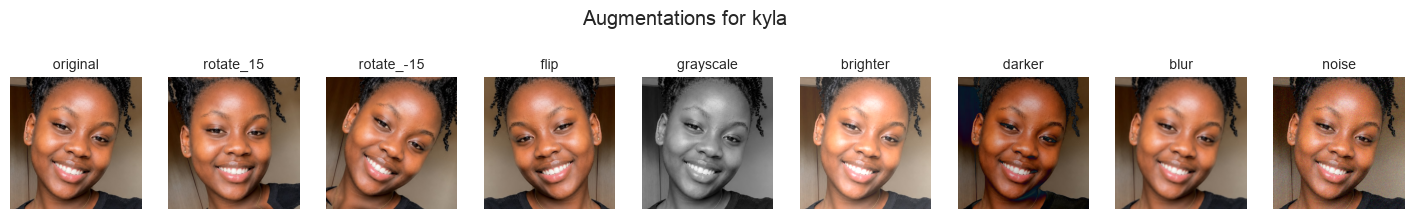

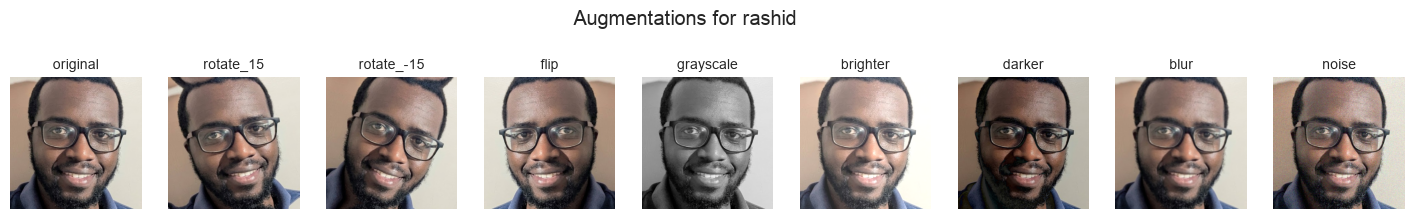

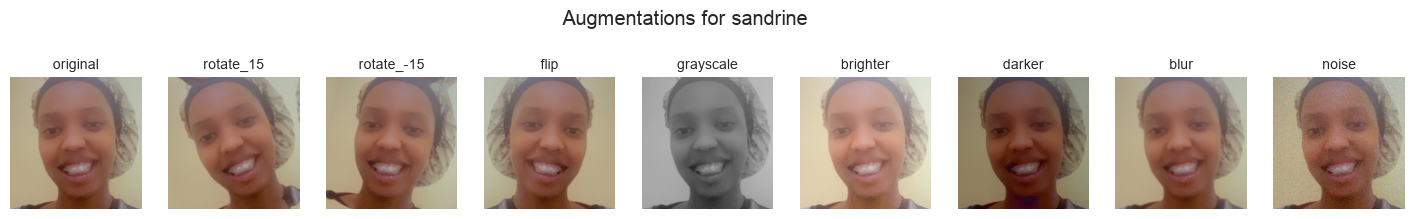

In [5]:
for m in members:
    path = lookup.get((m, "smiling")) or next(p for mm, _, p in images if mm == m)
    face, _ = detect_face(load_image(path))
    versions = augment(face)
    fig, axes = plt.subplots(1, len(versions), figsize=(2 * len(versions), 2.4))
    for ax, (name, img) in zip(axes, versions.items()):
        show(img, ax, name)
    plt.suptitle(f"Augmentations for {m}", y=1.05)
    plt.show()

## 4. Feature extraction

For every version of every face (resized to 128x128):

- HOG (histogram of oriented gradients) on the grayscale face, which captures face shape and edges
- HSV colour histograms (16 bins per channel)
- grayscale intensity histogram (32 bins)

In [6]:
df = build_feature_table(IMAGES_DIR)
df.to_csv("features/image_features.csv", index=False)
feature_cols = [c for c in df.columns if c not in face_model.META_COLS]
print(f"image_features.csv: {df.shape[0]} rows, {len(feature_cols)} features")
df[face_model.META_COLS + feature_cols[:3]].head()

image_features.csv: 108 rows, 1844 features


,member,expression,source_file,augmentation,hog_0,hog_1,hog_2
0,belyse,neutral,data/images/belyse/neutral.jpg,original,0.162299,0.061015,0.014987
1,belyse,neutral,data/images/belyse/neutral.jpg,rotate_15,0.291880,0.275931,0.035450
2,belyse,neutral,data/images/belyse/neutral.jpg,rotate_-15,0.097834,0.103606,0.113376
3,belyse,neutral,data/images/belyse/neutral.jpg,flip,0.206882,0.153191,0.025853
4,belyse,neutral,data/images/belyse/neutral.jpg,grayscale,0.161086,0.061878,0.015487


In [7]:
df.groupby(["member", "augmentation"]).size().unstack()

augmentation,blur,brighter,darker,flip,grayscale,noise,original,rotate_-15,rotate_15
member,,,,,,,,,
belyse,3,3,3,3,3,3,3,3,3
kyla,3,3,3,3,3,3,3,3,3
rashid,3,3,3,3,3,3,3,3,3
sandrine,3,3,3,3,3,3,3,3,3


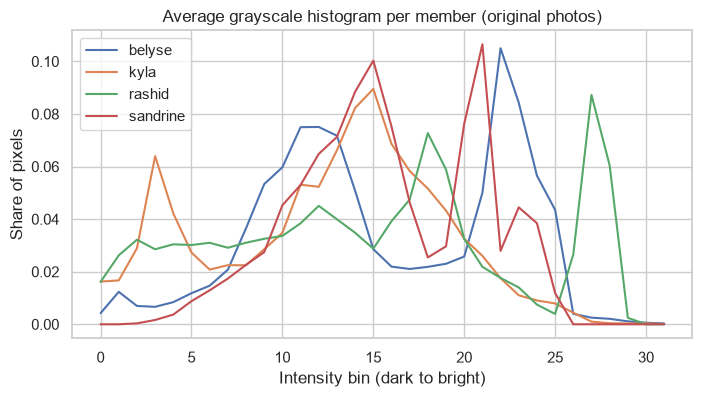

In [8]:
gray_cols = [c for c in feature_cols if c.startswith("hist_gray")]
originals = df[df["augmentation"] == "original"]
fig, ax = plt.subplots(figsize=(8, 4))
for m in members:
    ax.plot(originals.loc[originals["member"] == m, gray_cols].mean().values, label=m)
ax.set_xlabel("Intensity bin (dark to bright)")
ax.set_ylabel("Share of pixels")
ax.set_title("Average grayscale histogram per member (original photos)")
ax.legend()
plt.show()

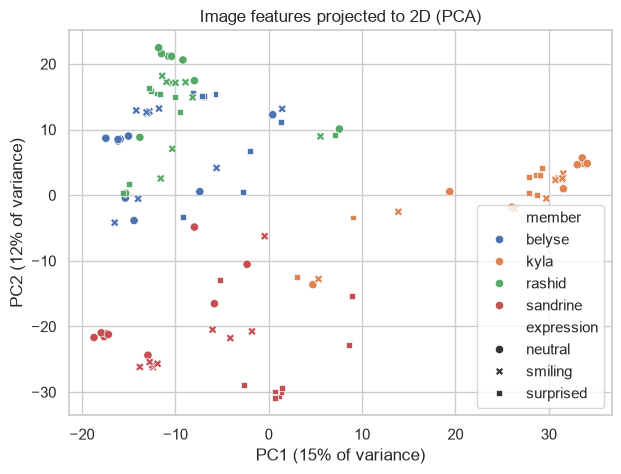

In [9]:
pca = PCA(n_components=2)
coords = pca.fit_transform((df[feature_cols] - df[feature_cols].mean()) / (df[feature_cols].std() + 1e-8))
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["member"], style=df["expression"], ax=ax)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Image features projected to 2D (PCA)")
plt.show()

## 5. Facial recognition model

Evaluation is leave-one-expression-out: the model is trained on two expressions (with their augmentations) and tested on the third, which it has never seen in any form. This is repeated three times, once per expression.

Three models are compared on accuracy, macro F1 and log loss.

In [10]:
results, confidences = face_model.evaluate(df)
results.round(3)

,model,held_out,accuracy,f1,log_loss
0,logistic_regression,neutral,1.000,1.000,0.041
1,logistic_regression,smiling,1.000,1.000,0.025
2,logistic_regression,surprised,1.000,1.000,0.046
3,random_forest,neutral,1.000,1.000,0.456
4,random_forest,smiling,1.000,1.000,0.431
5,random_forest,surprised,1.000,1.000,0.615
6,xgboost,neutral,0.889,0.887,0.361
7,xgboost,smiling,0.639,0.627,0.757
8,xgboost,surprised,0.583,0.538,1.144


In [11]:
summary = results.groupby("model")[["accuracy", "f1", "log_loss"]].mean().round(3)
summary

,accuracy,f1,log_loss
model,,,
logistic_regression,1.000,1.000,0.037
random_forest,1.000,1.000,0.501
xgboost,0.704,0.684,0.754


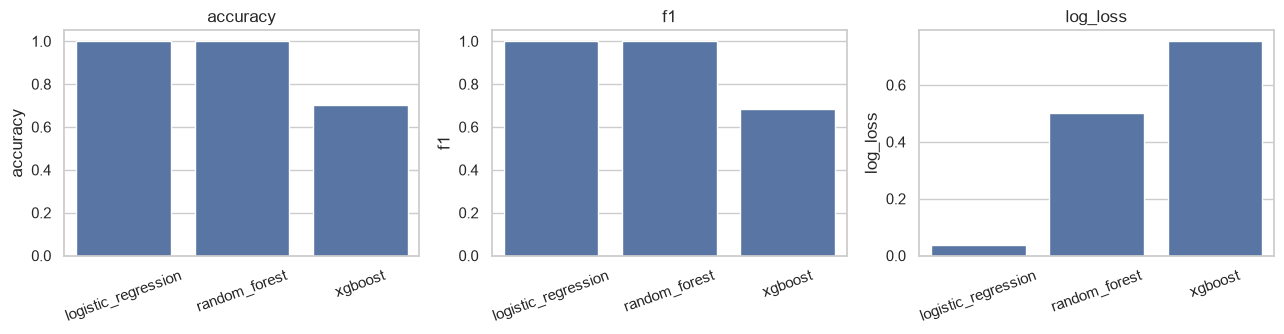

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric in zip(axes, ["accuracy", "f1", "log_loss"]):
    sns.barplot(data=results, x="model", y=metric, ax=ax, errorbar=None)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Best model: logistic_regression


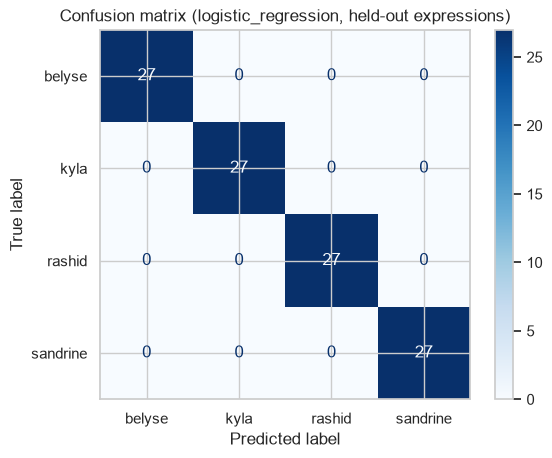

In [13]:
best = summary["f1"].idxmax()
print("Best model:", best)
y_true, y_pred = face_model.held_out_predictions(df, best)
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=members), display_labels=members).plot(cmap="Blues")
plt.title(f"Confusion matrix ({best}, held-out expressions)")
plt.show()

### Which features does the model rely on?

The same evaluation run on each feature group separately: HOG (face shape) only, and histograms (colour and lighting) only.

In [14]:
groups = {"HOG only": "hog_", "histograms only": "hist_"}
rows = []
for label, prefix in groups.items():
    cols = face_model.META_COLS + [c for c in feature_cols if c.startswith(prefix)]
    res, _ = face_model.evaluate(df[cols])
    s = res.groupby("model")[["accuracy", "f1", "log_loss"]].mean()
    s.insert(0, "features", label)
    rows.append(s)
pd.concat(rows).round(3)

,features,accuracy,f1,log_loss
model,,,,
logistic_regression,HOG only,1.000,1.000,0.042
random_forest,HOG only,1.000,1.000,0.498
xgboost,HOG only,0.694,0.670,0.807
logistic_regression,histograms only,0.917,0.898,0.309
random_forest,histograms only,1.000,1.000,0.354
xgboost,histograms only,0.954,0.954,0.244


## 6. Final model and rejecting unknown faces

A classifier always picks one of the known members, so two checks are used before a face is accepted:

1. the model's confidence must be above a threshold
2. the face must be close enough (cosine distance) to that member's own training images

The distance threshold comes from the held-out photos above.

Saved models/face_model.pkl (logistic_regression)
Confidence threshold: 0.915
Distance threshold:   0.563


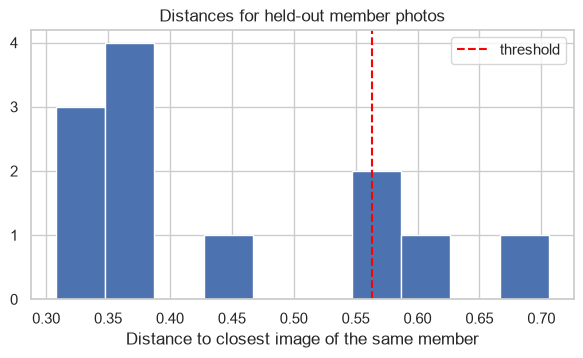

In [15]:
distances = face_model.genuine_distances(df)
bundle = face_model.train_final(df, best, confidences, distances)
face_model.save(bundle, "models/face_model.pkl")
print(f"Saved models/face_model.pkl ({best})")
print(f"Confidence threshold: {bundle['threshold']:.3f}")
print(f"Distance threshold:   {bundle['distance_threshold']:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(distances, bins=10)
ax.axvline(bundle["distance_threshold"], color="red", linestyle="--", label="threshold")
ax.set_xlabel("Distance to closest image of the same member")
ax.set_title("Distances for held-out member photos")
ax.legend()
plt.show()

## 7. Test: known members and an unauthorized face

In [16]:
tests = [(m, lookup[(m, "neutral")]) for m in members if (m, "neutral") in lookup]
if os.path.isdir(UNAUTHORIZED_DIR):
    tests += [("unauthorized", os.path.join(UNAUTHORIZED_DIR, f)) for f in sorted(os.listdir(UNAUTHORIZED_DIR))
              if f.lower().endswith((".jpg", ".jpeg", ".png"))]

rows = []
for who, path in tests:
    member, conf, dist = face_model.predict_face(path, bundle)
    rows.append({"photo of": who, "file": os.path.basename(path), "predicted": member or "ACCESS DENIED",
                 "confidence": round(conf, 3), "distance": round(dist, 3)})
pd.DataFrame(rows)

,photo of,file,predicted,confidence,distance
0,belyse,neutral.jpg,belyse,0.999,0.0
1,kyla,neutral.jpg,kyla,0.999,0.0
2,rashid,neutral.jpg,rashid,0.999,0.0
3,sandrine,neutral.jpg,sandrine,0.998,0.0


## Summary

For my part I worked on the facial images and the face recognition model. Each of us took three photos (neutral, smiling and surprised), but they came in different ways: mine were iPhone HEIC files and Ali's were inside a Word document, with two expressions in one picture. I first had to convert, split and rename everything so every member has the same three files (`neutral.jpg`, `smiling.jpg`, `surprised.jpg`) in their own folder.

The first face detector I used (OpenCV's Haar cascade) failed on my own photos because of the bright window behind me. It cut off my mouth and missed my face completely in one photo, so I switched to the YuNet detector, which found all 12 faces. I then made 8 augmented versions of every face (rotation both ways, flip, grayscale, brighter, darker, blur and noise) and extracted HOG and colour histogram features, giving 108 rows in `image_features.csv`.

To test the models fairly, I trained on two expressions and tested on the third, so the model never saw the test photo in any form. I compared the models on accuracy, F1 and log loss. Logistic Regression and Random Forest both got every photo right, but Logistic Regression had a much lower log loss (0.04 against 0.50), so it was more confident when it was right, and I kept it. XGBoost only reached about 70%, probably because there is so little data. A perfect score made me suspicious, so I tested face shape (HOG) alone and still got 100%, which showed the model was really looking at faces and not just the background.

In the full system this model is the first check: if the face is not recognised, the user is denied before the product model or the voice check is reached. What I learned is that with only four people and a few photos each, the model can easily pick up on lighting and background, and a classifier will always pick someone. That is why I added a second check on how close the face is to that member's own photos, so a stranger can be rejected.